# Fase 1 — Análisis Exploratorio de Datos (EDA)
**Objetivo:** entender el dataset de totalizadores horarios de la planta y justificar un subconjunto
manejable e informativo de variables para predecir `Frio (kW)` del día siguiente.

Hipótesis de partida, hoja por hoja (se contrastan con números más abajo):

| Hoja | Hipótesis sobre su relación con el consumo de frío |
|---|---|
| Consolidado EE | Contiene el target. `Servicios` y `Sala Maq` incluyen al frío → correlación muy alta. `Elaboración`/`Bodega` (fermentación y maduración) deberían arrastrar frío. |
| Totalizadores Energia | Los compresores `Mycom 1-7` **son** el sistema de frío medido desde otro tablero → redundantes con el target. Condensadores evaporativos: carga térmica. |
| Consolidado / Totalizadores Produccion | Más mosto y más cerveza en bodega = más calor a remover, con retardo de días (fermentación). |
| Consolidado KPI | Ratios por Hl y **metas**: las metas cambian por mes → proxy de estacionalidad, no de operación. |
| Agua / Aire / GasVapor / CO2 / Efluentes / Glicol | Indirectas: el agua de los condensadores evaporativos sube con la carga del frío; el resto, relación débil esperable. |

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import auxiliar_functions as af
import preprocessing_pipeline as pp
SEMILLA = af.SEMILLA
np.random.seed(SEMILLA)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
FIG = af.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
T = af.TARGET
files = af.find_excels()
[f.name for f in files]

['Totalizadores_Planta_-_2021_2023.xlsx',
 'Totalizadores_Planta_2020_2022.xlsx',
 'Totalizadores_Planta_2022_2023.xlsx']

## 1.1 Análisis descriptivo y versionado inicial
### Estructura de los archivos
Los nombres de los archivos recibidos no coinciden con los del enunciado (`2020_2022`, `2021_2023`, `2022_2023`):
el código los busca con el patrón `Totalizadores*Planta*.xlsx`, así que funciona con ambos nombres.

In [2]:
raw_ee = {}
for f in files:
    sh = af.read_excel_sheets(f)  # todas las hojas conocidas, por nombre
    raw_ee[f.name] = sh[af.TARGET_SHEET]
    print(f"{f.name}: {len(sh)} hojas de datos")
    print("   ", {s: df.shape for s, df in sh.items()})

Totalizadores_Planta_-_2021_2023.xlsx: 14 hojas de datos
    {'Consolidado EE': (15450, 21), 'Totalizadores Energia': (15316, 59), 'Consolidado Produccion': (15317, 13), 'Totalizadores Produccion': (15316, 40), 'Consolidado KPI': (15317, 123), 'Consolidado Agua': (15451, 24), 'Totalizadores Agua': (15316, 43), 'Consolidado GasVapor': (15460, 20), 'Totalizadores Gas y Vapor': (15316, 23), 'Consolidado Aire': (15649, 14), 'Totalizadores Aire': (15316, 11), 'Totalizadores CO2': (15317, 8), 'Totalizadores Efluentes': (15316, 8), 'Totalizadores Glicol': (15316, 7)}


Totalizadores_Planta_2020_2022.xlsx: 14 hojas de datos
    {'Consolidado EE': (16054, 21), 'Totalizadores Energia': (15575, 53), 'Consolidado Produccion': (15573, 12), 'Totalizadores Produccion': (15573, 40), 'Consolidado KPI': (16049, 62), 'Consolidado Agua': (16049, 18), 'Totalizadores Agua': (15575, 43), 'Consolidado GasVapor': (16049, 17), 'Totalizadores Gas y Vapor': (15575, 22), 'Consolidado Aire': (15912, 14), 'Totalizadores Aire': (15575, 11), 'Totalizadores CO2': (15575, 8), 'Totalizadores Efluentes': (15575, 8), 'Totalizadores Glicol': (15563, 8)}


Totalizadores_Planta_2022_2023.xlsx: 14 hojas de datos
    {'Consolidado EE': (12011, 21), 'Totalizadores Energia': (12009, 54), 'Consolidado Produccion': (12010, 18), 'Totalizadores Produccion': (12009, 41), 'Consolidado KPI': (12010, 125), 'Consolidado Agua': (12011, 24), 'Totalizadores Agua': (12009, 44), 'Consolidado GasVapor': (12011, 20), 'Totalizadores Gas y Vapor': (12009, 24), 'Consolidado Aire': (12011, 14), 'Totalizadores Aire': (12009, 12), 'Totalizadores CO2': (12009, 9), 'Totalizadores Efluentes': (12009, 9), 'Totalizadores Glicol': (12009, 8)}


### Registros por fecha: ¿hay jornadas apiladas bajo la misma etiqueta?

In [3]:
filas = []
for k, df in raw_ee.items():
    h = af.prepare_hourly(df, af.TARGET_SHEET)
    c = h.groupby("DIA").size()
    filas.append(c.value_counts().sort_index().rename(k))
    raras = c[c > 25]
    print(f"{k}: {len(raras)} fechas con >25 registros ->", [f"{d.date()}({n})" for d, n in raras.items()])
pd.concat(filas, axis=1).fillna(0).astype(int).rename_axis("registros por fecha")

Totalizadores_Planta_-_2021_2023.xlsx: 8 fechas con >25 registros -> ['2021-09-30(50)', '2021-11-30(50)', '2022-02-28(100)', '2022-04-30(50)', '2022-06-30(51)', '2022-09-30(50)', '2022-11-30(50)', '2023-02-28(99)']
Totalizadores_Planta_2020_2022.xlsx: 8 fechas con >25 registros -> ['2020-09-30(50)', '2020-11-30(50)', '2021-02-28(100)', '2021-04-30(50)', '2021-06-30(51)', '2021-09-30(50)', '2021-11-30(50)', '2022-02-28(100)']
Totalizadores_Planta_2022_2023.xlsx: 6 fechas con >25 registros -> ['2022-09-30(50)', '2022-11-30(50)', '2023-02-28(99)', '2023-04-30(50)', '2023-06-30(51)', '2023-09-30(50)']


,Totalizadores_Planta_-_2021_2023.xlsx,Totalizadores_Planta_2020_2022.xlsx,Totalizadores_Planta_2022_2023.xlsx
registros por fecha,,,
9,1,0,0
16,1,0,1
23,3,2,1
24,3,5,0
25,586,596,463
50,5,5,4
51,1,1,1
99,1,0,1
100,1,2,0


**Hallazgo:** las fechas con 50, 51, 99 o 100 registros son siempre **el último día de un mes con menos de 31 días**
(30/09, 30/11, 30/04, 30/06, 28/02). La planilla tiene 31 renglones de día por mes y los días inexistentes
(31/09, 29-31/02…) quedaron etiquetados con la última fecha válida. Cada bloque arranca otra vez en 00:00 y
tiene valores distintos, así que **son jornadas distintas apiladas** y no duplicados. Como no se puede saber cuál
es la real, esas fechas se marcan inválidas. Sin esto, `shift(-1)` alinearía el día D con un bloque fantasma.

In [4]:
d = raw_ee[files[-1].name]; h = af.prepare_hourly(d, af.TARGET_SHEET)
ej = h[h.DIA == "2023-02-28"]
ej.groupby("bloque").agg(registros=("MIN", "size"), primera_hora=("HORA", "first"),
                         ultima_hora=("HORA", "last"), frio_final=("Frio (Kw)", "last"))

,registros,primera_hora,ultima_hora,frio_final
bloque,,,,
0,24,00:00:00,23:00:00,15279.0
1,25,00:00:00,23:59:00,20857.0
2,25,00:00:00,23:59:00,21015.0
3,25,00:00:00,23:59:00,23398.0


### Unificación y solapamiento entre archivos

In [5]:
unified, qc, overlap = pp.unify_files(files)
print(json.dumps({k: v for k, v in overlap.items() if k != "detalle_distintas"}, indent=2, ensure_ascii=False))
pd.DataFrame(overlap["detalle_distintas"]).T

{
  "fechas_en_mas_de_un_archivo": 498,
  "fechas_comparables": 493,
  "fechas_con_total_identico": 488,
  "fechas_con_total_distinto": 5,
  "regla_desempate": "dia valido > archivo con fecha final mas reciente"
}


,Totalizadores_Planta_-_2021_2023.xlsx,Totalizadores_Planta_2020_2022.xlsx,Totalizadores_Planta_2022_2023.xlsx
2021-07-28,30764.0,2900770.0,NaN
2021-08-25,37122.0,2907122.0,NaN
2021-11-28,25719.0,6155928.0,NaN
2022-02-02,19887.0,52655.0,NaN
2022-02-18,21470.0,8861470.0,NaN


Los archivos se solapan en cientos de fechas y en la enorme mayoría el total diario de Frio es **idéntico**.
Las pocas discrepancias son siempre del archivo más viejo (`2020_2022`) con valores imposibles (millones) o
claramente corregidos en la extracción posterior.

**Regla de desempate:** por fecha, entre los archivos donde el día es *válido*, gana el de fecha final más reciente
(extracción posterior, que incorpora correcciones). Si solo un archivo tiene el día válido, gana ese.

### Checksums (SHA-256)

In [6]:
unified_path = pp.INTERIM_DIR / "dataset_unificado.csv"
pp.INTERIM_DIR.mkdir(parents=True, exist_ok=True)
unified.to_csv(unified_path, float_format="%.6f")
ck = af.update_checksums(files + [unified_path])
ck

{'data/Totalizadores_Planta_-_2021_2023.xlsx': 'b4dbfacd0fd8d7720ec6dfc09dc593fac479d78a7c17ea671692590dc85f90fb',
 'data/Totalizadores_Planta_2020_2022.xlsx': '7bb3474c1686712eed9634b1afc757540766dad56c15580a866a3145ad9c53d7',
 'data/Totalizadores_Planta_2022_2023.xlsx': 'aba9f9ff11e6fa477af282f14a88354f8a55c782941d5a4eb403e4c742e6df98',
 'data/interim/dataset_unificado.csv': '53b5fd716ee401503a6bb70b6406d6cff9a7f2dd4ce3ef4a0e3c81a1b382431d',
 'data/processed/dataset_final.csv': '999ec67043ba46be844b36d351417aebd40c319b61eae67909c603a1e0aa26ca'}

`huella()` lee por bloques de 1 MiB, así que no carga los ~30 MB de cada Excel en memoria.
**Por qué no MD5:** MD5 tiene colisiones prácticas conocidas (dos archivos distintos con el mismo hash), por lo que
no garantiza que quien clona tenga exactamente los mismos datos; SHA-256 no tiene colisiones conocidas.

### Dimensiones, tipos y rangos del dataset unificado (diario)

In [7]:
daily = unified[[c for c in unified.columns if not c.startswith("_")]]
num = daily.select_dtypes("number")
print("Dimensiones (días x variables):", daily.shape)
print("Rango de fechas:", daily.index.min().date(), "->", daily.index.max().date())
print("Tipos:", daily.dtypes.value_counts().to_dict())
hojas = pd.Series([c.split("__")[0] for c in daily.columns]).value_counts()
print("Variables por hoja:", hojas.to_dict())
num[[T, "EE__Planta (Kw)", "EE__Servicios (Kw)", "PROD__Hl de Mosto", "PROD__Hl Cerveza Envasada",
     "AGUA__Agua Planta (Hl)"]].describe().T.round(1)

Dimensiones (días x variables): (1213, 397)
Rango de fechas: 2020-07-01 -> 2023-10-26
Tipos: {dtype('float64'): 397}
Variables por hoja: {'KPI': 110, 'TEN': 51, 'TAGUA': 41, 'EE': 40, 'TPROD': 39, 'AGUA': 22, 'TGV': 22, 'GV': 19, 'AIRE': 12, 'PROD': 11, 'TAIRE': 9, 'GLI': 9, 'CO2': 6, 'EFL': 6}


,count,mean,std,min,25%,50%,75%,max
EE__Frio (Kw),1165.0,23535.6,7602.9,2310.0,17859.0,23684.0,29187.0,48046.0
EE__Planta (Kw),1165.0,63696.3,16782.8,13210.8,51708.9,66805.9,76618.2,117956.2
EE__Servicios (Kw),1165.0,38703.0,9946.7,8087.0,31412.0,39052.0,46409.0,65902.5
PROD__Hl de Mosto,1164.0,5479.7,2764.1,0.0,3835.2,6457.5,7560.8,9823.0
PROD__Hl Cerveza Envasada,1164.0,8486.2,4154.2,0.0,5787.0,9341.5,11657.2,15989.0
AGUA__Agua Planta (Hl),1165.0,32179.8,8313.6,4963.8,26570.0,33520.2,38528.2,54361.0


### Valores faltantes

Días de calendario: 1213 | días con target válido: 1165
Variables 100% vacías: 1 | >50% vacías: 10 | sin faltantes fuera de días inválidos: 193


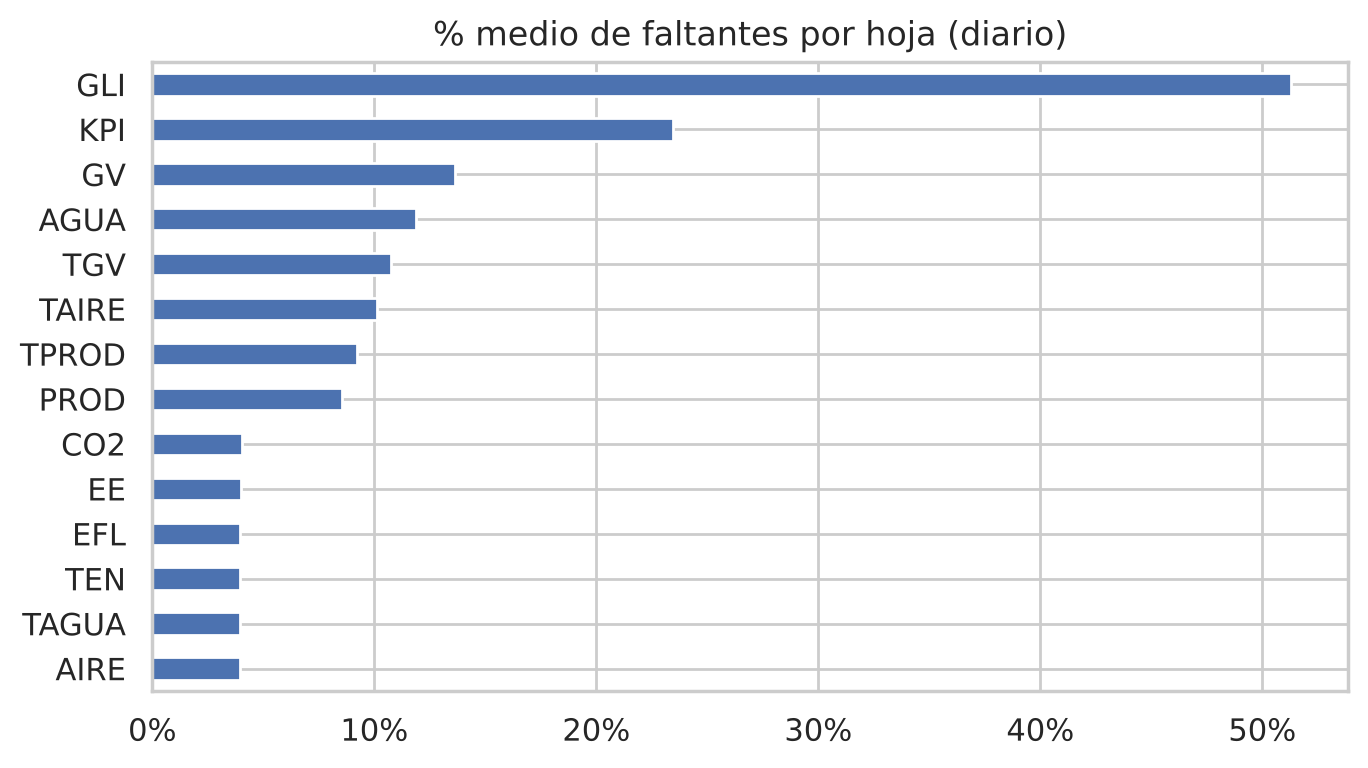

In [8]:
na = daily.isna().mean().sort_values(ascending=False)
print(f"Días de calendario: {len(daily)} | días con target válido: {daily[T].notna().sum()}")
print(f"Variables 100% vacías: {(na == 1).sum()} | >50% vacías: {(na > .5).sum()} | sin faltantes fuera de días inválidos: {(na <= daily[T].isna().mean() + 1e-9).sum()}")
por_hoja = na.groupby([c.split("__")[0] for c in na.index]).mean().sort_values()
ax = por_hoja.plot.barh(figsize=(7, 4), title="% medio de faltantes por hoja (diario)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.savefig(FIG / "faltantes_por_hoja.png", dpi=120); plt.show()

Los faltantes tienen dos orígenes: (1) **días inválidos**, que se vacían completos; (2) **columnas que no existen en
todos los archivos** (p. ej. las metas de KPI y `Agua Cond Evaporativos` no están en `2020_2022`), que quedan vacías
en ese tramo. Ninguna de las variables candidatas finales depende de esas columnas, salvo `eficiencia_frio`, que la
imputación por mediana (ajustada en train) cubre y la selección de variables termina descartando.

### Registros inválidos y valores atípicos del target

In [9]:
cols = ["incompleto", "imposible", "sin_reinicio", "apilado", "danado"]
tab = qc[cols + ["valido"]].groupby(level="archivo").sum().astype(int)
tab["n_saltos>0"] = (qc["n_saltos"] > 0).groupby(level="archivo").sum()
tab

,incompleto,imposible,sin_reinicio,apilado,danado,valido,n_saltos>0
archivo,,,,,,,
Totalizadores_Planta_-_2021_2023.xlsx,5,0,1,8,1,588,30
Totalizadores_Planta_2020_2022.xlsx,3,11,2,8,2,599,43
Totalizadores_Planta_2022_2023.xlsx,5,0,0,6,0,463,8


Criterios (aplicados sobre `Frio (Kw)` de *Consolidado EE*, por fecha):
- **incompleto**: menos de 24 lecturas horarias o arranque después de las 00:00 → el totalizador final no es el del día.
  Si solo falta la lectura de las 23:59, el total **se estima** desde las 23:00 con el ritmo de las últimas 3 horas (validado en la Fase 2).
- **imposible**: algún valor ≥ 1.000.000 (el rango físico diario es 0–60.000). En Frio es un salto del totalizador y **se reconstruye**
  (ver saltos); en el resto de las columnas, los valores de ese orden se ponen en NaN.
- **sin_reinicio**: la jornada no arranca en 0 a las 00:00. El total de Frio se arma como suma de incrementos, así que el arrastre
  del día anterior no cuenta y el día **se conserva**.
- **apilado**: más de una jornada bajo la misma fecha (ver arriba). La reasignación a las fechas faltantes se evalúa en la Fase 2.
- **saltos**: incrementos horarios negativos o > 3.000 kW (el p99,9 de los incrementos del archivo más limpio es ~2.000).
  Con hasta 2 saltos, el total se **corrige** reemplazando el salto por la mediana horaria del día; con más, el día se descarta.

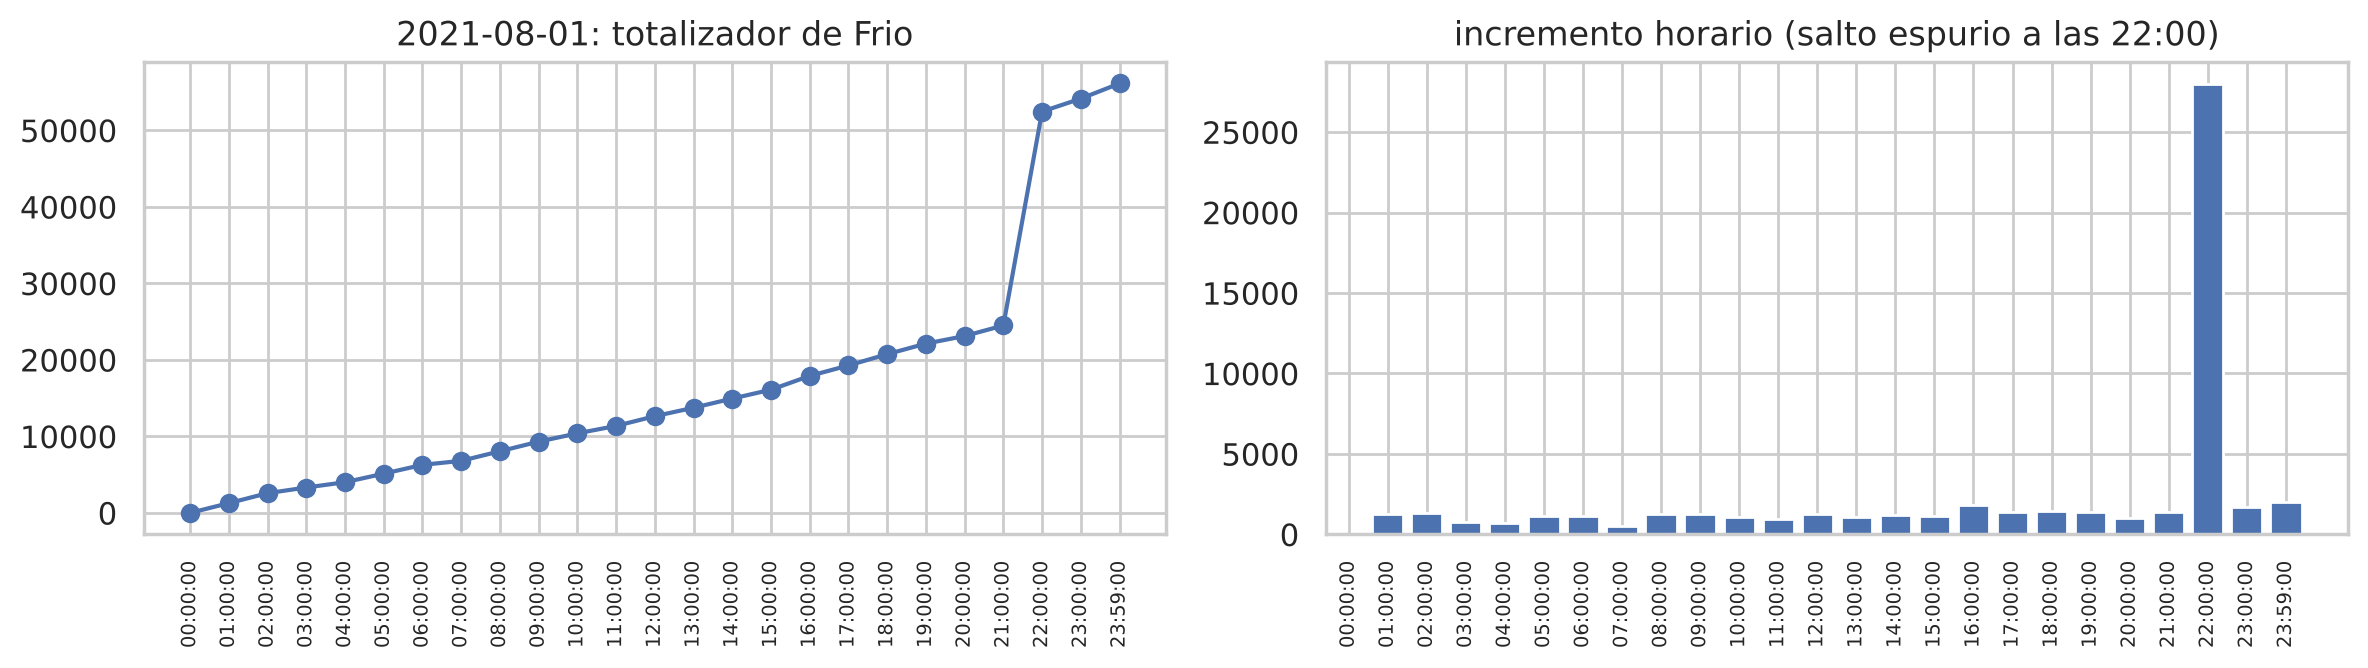

Total crudo 23:59 = 56,128 kW  ->  corregido = 29,416 kW


In [10]:
h = af.prepare_hourly(raw_ee[files[1].name], af.TARGET_SHEET)
dia = h[(h.DIA == "2021-08-01") & (h.bloque == 0)]
inc = dia["Frio (Kw)"].diff()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(dia["HORA"], dia["Frio (Kw)"], marker="o"); ax[0].set_title("2021-08-01: totalizador de Frio")
ax[1].bar(dia["HORA"], inc); ax[1].set_title("incremento horario (salto espurio a las 22:00)")
for a in ax: a.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "salto_espurio.png", dpi=120); plt.show()
q = qc.xs(files[1].name, level="archivo").loc["2021-08-01"]
print(f"Total crudo 23:59 = {q.valor_2359:,.0f} kW  ->  corregido = {q.valor_corregido:,.0f} kW")

### ¿23:00 o 23:59? Definición del total diario

In [11]:
dif = (qc["valor_2359"] - qc["valor_2300"])[qc["valido"] & (qc["n_saltos"] == 0)]
print(f"Diferencia 23:59 - 23:00 en días válidos sin saltos: media {dif.mean():,.0f} kW, mediana {dif.median():,.0f} kW, "
      f"= {(dif / qc.loc[dif.index, 'valor_2359']).median():.1%} del total diario")

Diferencia 23:59 - 23:00 en días válidos sin saltos: media 926 kW, mediana 913 kW, = 4.0% del total diario


**Decisión: total diario = lectura de las 23:59**, aplicada en todo el trabajo (features, target, baselines y `predict.py`).
Justificación: (1) la documentación del dataset define el 23:59 como el total del día; (2) la lectura de las 23:00 deja
afuera la última hora (~900 kW, ~4 % del día), un sesgo sistemático del orden del 30 % del margen de error permitido;
(3) el día siguiente arranca en 0 a las 00:00, así que el 23:59 es el último valor antes del reinicio.

## 1.2 Análisis temporal

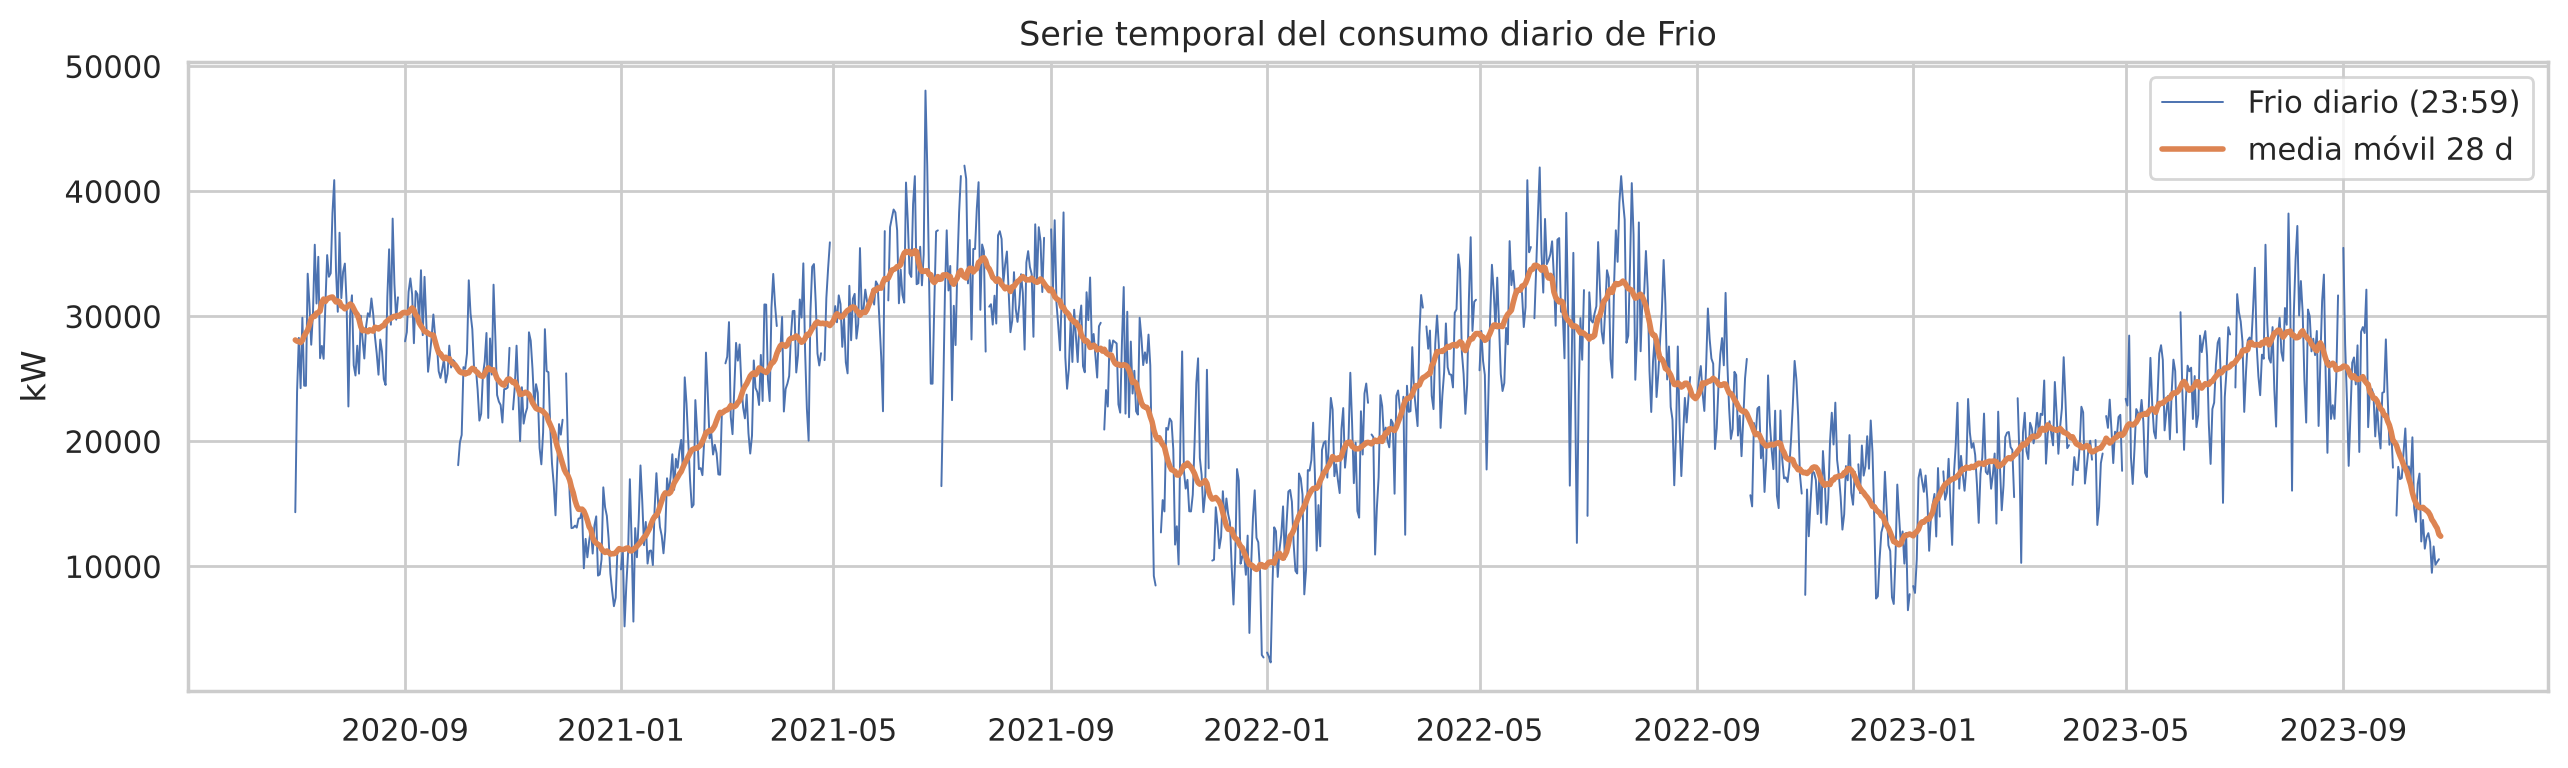

In [12]:
s = daily[T]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(s.index, s, lw=.7, label="Frio diario (23:59)")
ax.plot(s.index, s.rolling(28, min_periods=7, center=True).mean(), lw=2, label="media móvil 28 d")
ax.set_ylabel("kW"); ax.set_title("Serie temporal del consumo diario de Frio"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "serie_frio.png", dpi=120); plt.show()

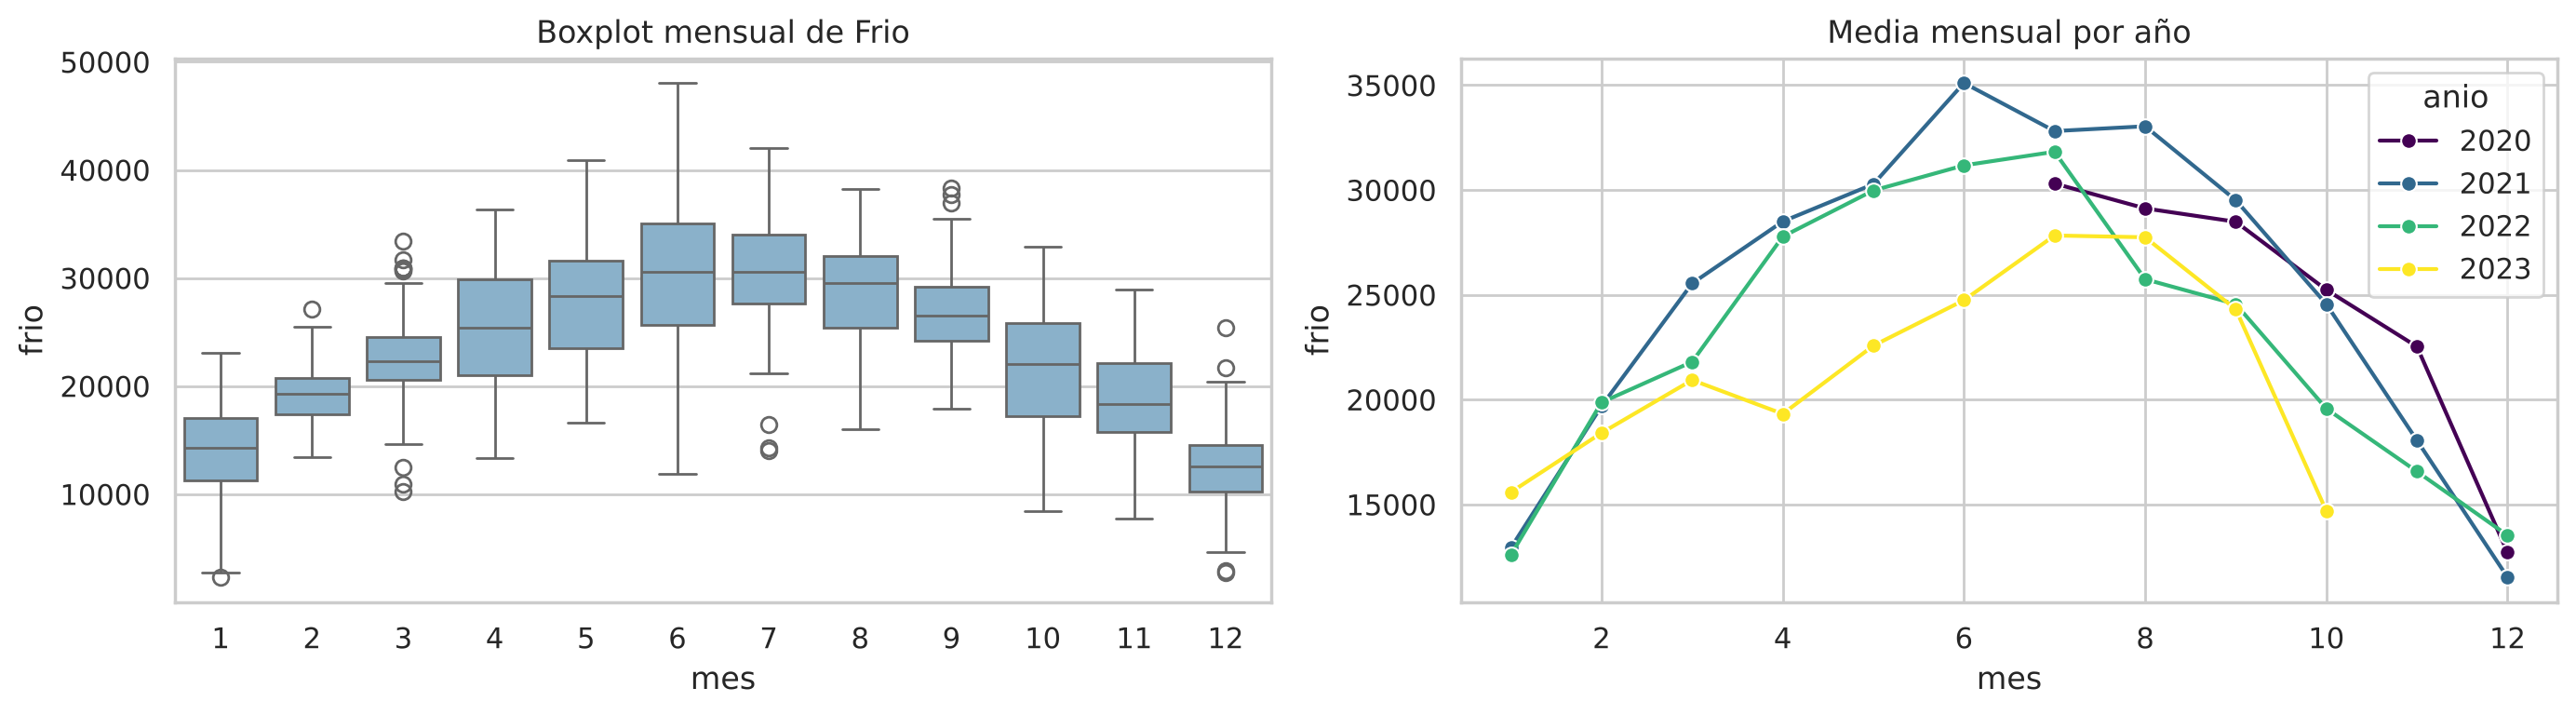

Mes más alto: 7 (30,680 kW) | más bajo: 12 (12,586 kW) | cociente 2.44x
Varianza explicada por el mes (eta²): 0.593


In [13]:
df = pd.DataFrame({"frio": s, "mes": s.index.month, "anio": s.index.year, "dow": s.index.dayofweek}).dropna()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="mes", y="frio", ax=ax[0], color="#7fb3d5"); ax[0].set_title("Boxplot mensual de Frio")
sns.lineplot(data=df.groupby(["anio", "mes"]).frio.mean().reset_index(), x="mes", y="frio", hue="anio",
             marker="o", ax=ax[1], palette="viridis"); ax[1].set_title("Media mensual por año")
plt.tight_layout(); plt.savefig(FIG / "estacionalidad_mensual.png", dpi=120); plt.show()
mens = df.groupby("mes").frio.mean()
print(f"Mes más alto: {mens.idxmax()} ({mens.max():,.0f} kW) | más bajo: {mens.idxmin()} ({mens.min():,.0f} kW) "
      f"| cociente {mens.max()/mens.min():.2f}x")
print("Varianza explicada por el mes (eta²):",
      round(1 - df.groupby('mes').frio.transform(lambda x: x - x.mean()).var() / df.frio.var(), 3))

Estacionalidad anual muy marcada: el verano (jun-ago) consume más del doble que diciembre-enero, en línea con la
temperatura de Tecate. Los mínimos absolutos (2.000-5.000 kW) son paradas de fin de año: son reales, no errores.

### Patrón diario (dentro del día)

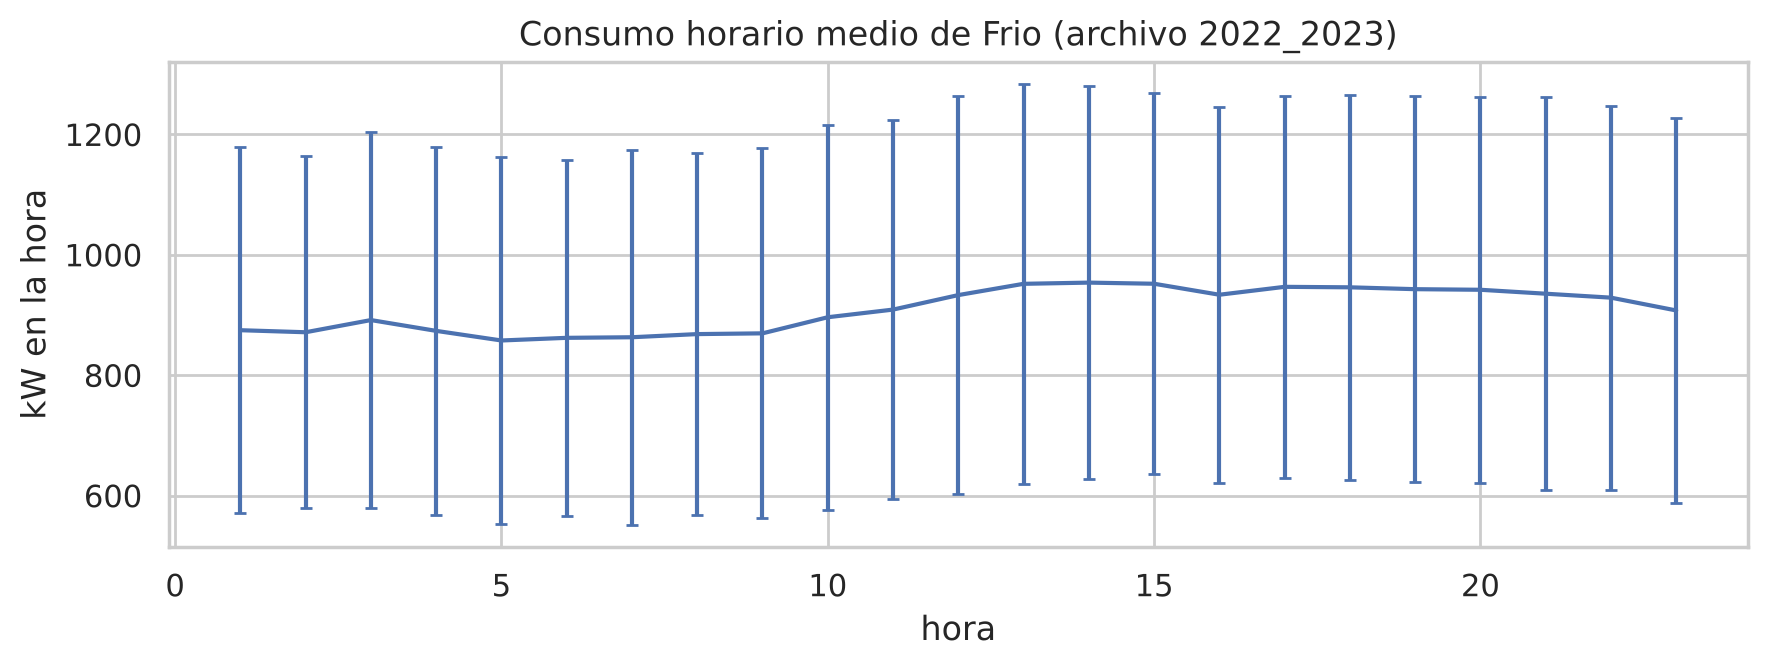

Coeficiente de variación del perfil medio horario: 3.9%


In [14]:
hh = af.prepare_hourly(raw_ee[files[-1].name], af.TARGET_SHEET)
hh = hh[hh.bloque == 0].sort_values(["DIA", "MIN"])
hh["inc"] = hh.groupby("DIA")["Frio (Kw)"].diff()
hh = hh[(hh.inc >= 0) & (hh.inc <= af.MAX_INC_HORARIO) & (hh.MIN % 60 == 0)]
perfil = hh.groupby(hh.MIN // 60)["inc"].agg(["mean", "std"])
ax = perfil["mean"].plot(yerr=perfil["std"], figsize=(9, 3.5), capsize=2, title="Consumo horario medio de Frio (archivo 2022_2023)")
ax.set_xlabel("hora"); ax.set_ylabel("kW en la hora")
plt.tight_layout(); plt.savefig(FIG / "perfil_horario.png", dpi=120); plt.show()
print(f"Coeficiente de variación del perfil medio horario: {perfil['mean'].std()/perfil['mean'].mean():.1%}")

El consumo horario es casi plano (CV del perfil medio bajo): el frío es una carga **base** continua, no sigue un turno.
Eso motiva usar el consumo de las últimas horas del día (`frio_ult6h`, `frio_ult12h`) como medida del ritmo con el que
termina la jornada D, que es lo más cercano al arranque de D+1.

### Patrón semanal: medirlo en lugar de asumirlo

ANOVA sobre el nivel:     F=1.01  p=0.415   eta²=0.005
ANOVA sin tendencia 28 d: F=4.85  p=0.000   eta²=0.024
Kruskal-Wallis (nivel):    p=0.472
Rango del efecto día-de-semana (sin tendencia): 1,796 kW vs desvío diario del residuo 3,673 kW


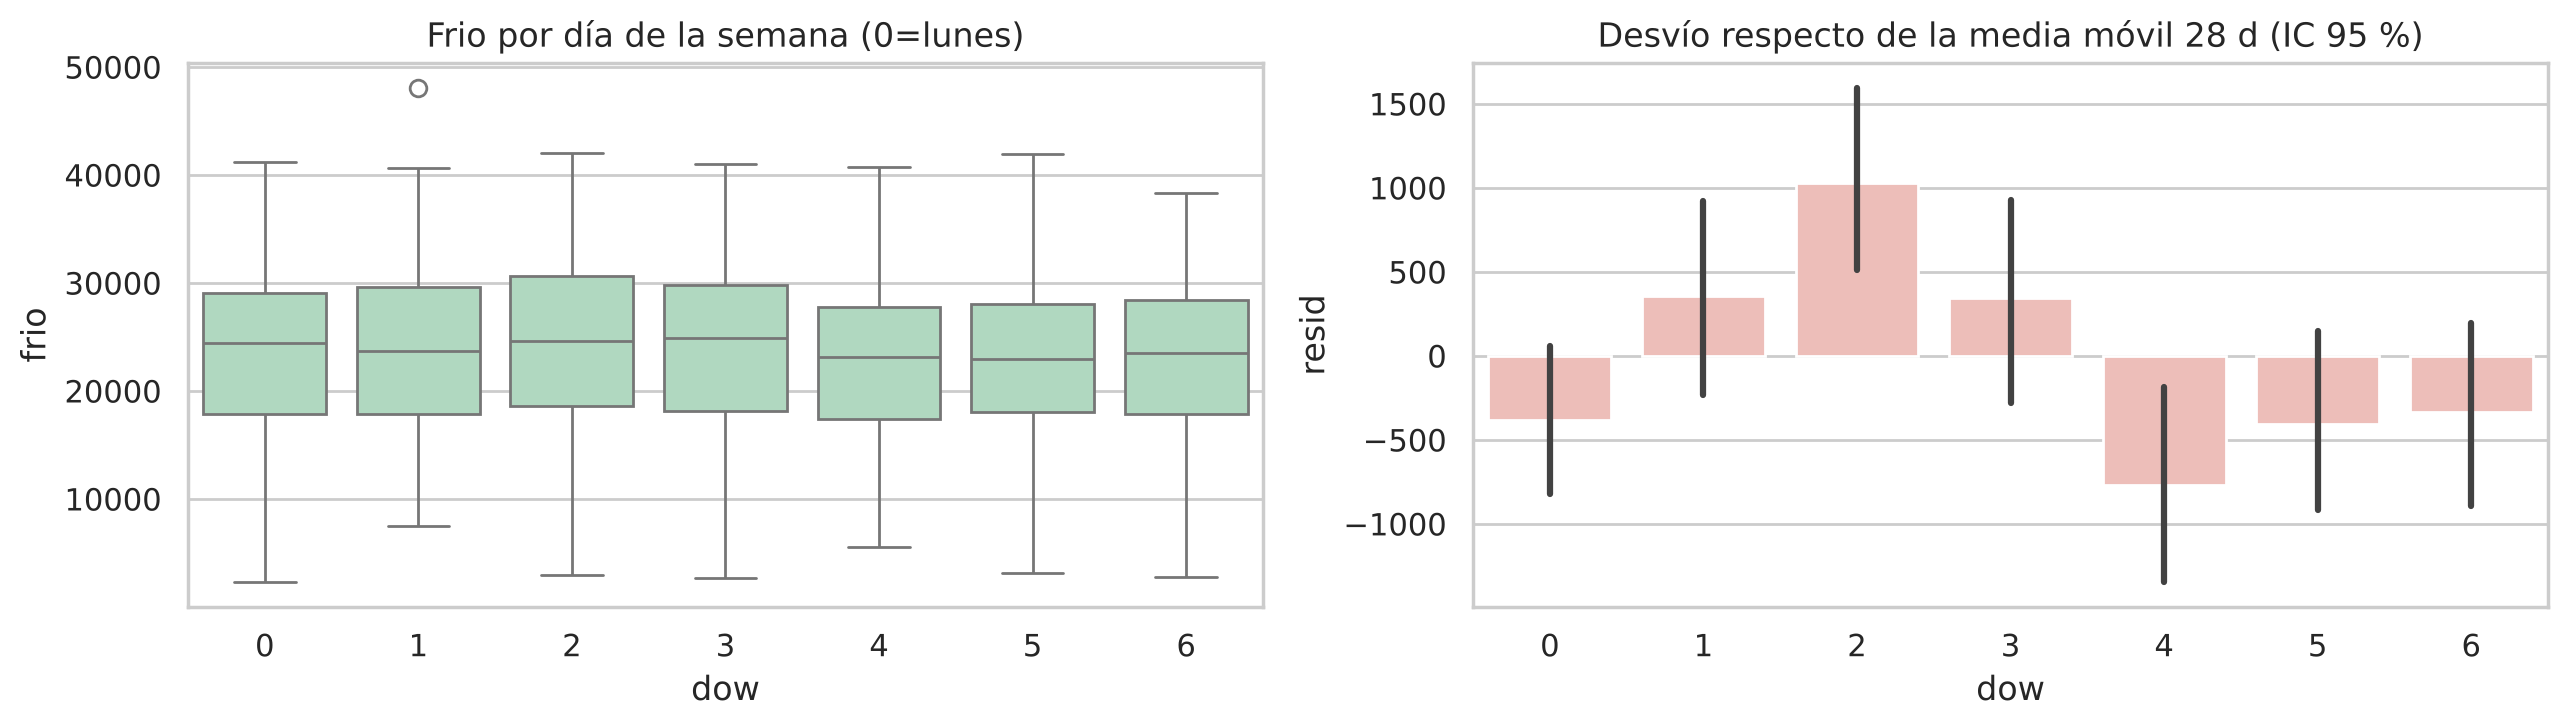

In [15]:
dfw = df.copy()
dfw["resid"] = dfw.frio - s.rolling(28, center=True, min_periods=14).mean().reindex(dfw.index)
dfw = dfw.dropna()
g_raw = [x.frio.values for _, x in dfw.groupby("dow")]
g_res = [x.resid.values for _, x in dfw.groupby("dow")]
eta2 = lambda col: 1 - dfw.groupby("dow")[col].transform(lambda x: x - x.mean()).var() / dfw[col].var()
print("ANOVA sobre el nivel:     F=%.2f  p=%.3f   eta²=%.3f" % (*stats.f_oneway(*g_raw), eta2("frio")))
print("ANOVA sin tendencia 28 d: F=%.2f  p=%.3f   eta²=%.3f" % (*stats.f_oneway(*g_res), eta2("resid")))
print("Kruskal-Wallis (nivel):    p=%.3f" % stats.kruskal(*g_raw).pvalue)
efecto = dfw.groupby("dow").resid.mean()
print(f"Rango del efecto día-de-semana (sin tendencia): {efecto.max()-efecto.min():,.0f} kW "
      f"vs desvío diario del residuo {dfw.resid.std():,.0f} kW")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(data=dfw, x="dow", y="frio", ax=ax[0], color="#a9dfbf"); ax[0].set_title("Frio por día de la semana (0=lunes)")
sns.barplot(data=dfw, x="dow", y="resid", ax=ax[1], color="#f5b7b1", errorbar=("ci", 95)); ax[1].set_title("Desvío respecto de la media móvil 28 d (IC 95 %)")
plt.tight_layout(); plt.savefig(FIG / "patron_semanal.png", dpi=120); plt.show()

**Resultado (con el número en la mano):**
- Sobre el nivel de consumo, el día de la semana explica **0,5 %** de la varianza y no es significativo (ANOVA p ≈ 0,42; Kruskal-Wallis p ≈ 0,47).
- Quitando la tendencia de 28 días aparece un efecto estadísticamente detectable (p < 0,001) pero chico: **eta² ≈ 0,02**.
  No hay un corte laborable/fin de semana: los sábados y domingos no se separan del resto (el máximo es miércoles y el mínimo viernes).

El enunciado y la documentación afirman un patrón semanal "laborables vs fin de semana"; **la medición no lo respalda**.
Explicación física: el frío es una carga base (fermentación, maduración y almacenamiento en frío corren 7×24) y la parte que sí
depende de turnos (envasado) casi no pasa por el sistema de frío (corr. Envasado–Frio ≈ 0). Además la estacionalidad anual
(cociente 2,4x entre julio y diciembre, eta² ≈ 0,59) tapa cualquier efecto semanal.
**Consecuencia:** `dia_semana` y `fin_de_semana` se construyen (trazabilidad) pero se **descartan** como candidatas. En
`preprocesamiento.ipynb` se verifica que agregarlas al modelo empeora el MAE de validación.

## Variabilidad de las métricas

In [16]:
valid = daily[unified["_valido"]].select_dtypes("number")
desc = pd.DataFrame({"std": valid.std(), "media": valid.mean(), "n_unicos": valid.nunique(),
                     "pct_na": valid.isna().mean()})
desc["cv"] = desc["std"] / desc["media"].abs().replace(0, np.nan)
casi_constantes = desc[(desc.n_unicos <= 2) | (desc["std"] == 0) | (desc.pct_na > .5)]
print(f"Variables numéricas: {len(desc)} | constantes / casi vacías: {len(casi_constantes)}")
print("Ejemplos:", casi_constantes.index[:12].tolist())

Variables numéricas: 397 | constantes / casi vacías: 31
Ejemplos: ['TEN__KW Linea 4', 'TEN__Kw llum/Serv L2', 'TPROD__HL Mosto Budweiser', 'TPROD__HL Mosto Local', 'TPROD__HL Mosto Fuerte', 'TPROD__HL Mosto Indio', 'TPROD__HL Mosto Palermo', 'TPROD__HL Mosto Bieckert', 'TPROD__HL Mosto Malta', 'TPROD__HL Mosto Frost', 'TPROD__Hl Session IPA', 'TPROD__Hl Reserva 8']


Las variables constantes, binarias o mayormente vacías no pueden explicar cambios en el consumo y se excluyen.

## 1.3 Correlaciones

In [17]:
ok = desc.drop(casi_constantes.index).index
y_next = s.shift(-1)
corr = pd.DataFrame({"mismo_dia": valid[ok].corrwith(valid[T]),
                     "dia_siguiente(y)": valid[ok].corrwith(y_next.reindex(valid.index))})
corr["hoja"] = [c.split("__")[0] for c in corr.index]
print("Máxima |correlación| con y por hoja:")
print(corr.assign(a=corr["dia_siguiente(y)"].abs()).groupby("hoja").a.max().sort_values(ascending=False).round(3).to_string())
top15 = corr.drop(index=T)["dia_siguiente(y)"].abs().sort_values(ascending=False).head(15).index
corr.loc[top15].round(3)

Máxima |correlación| con y por hoja:
hoja
EE       0.854
TEN      0.785
AGUA     0.701
KPI      0.686
TAGUA    0.607
AIRE     0.563
TAIRE    0.563
PROD     0.556
CO2      0.518
GV       0.453
TGV      0.437
TPROD    0.435
GLI      0.245
EFL      0.036


,mismo_dia,dia_siguiente(y),hoja
EE__Frio_ult12h,0.965,0.845,EE
EE__Frio (Kw)__ult6h,0.925,0.836,EE
EE__Frio_ult6h,0.925,0.836,EE
EE__Servicios (Kw),0.944,0.820,EE
EE__Servicios (Kw)__ult6h,0.877,0.806,EE
EE__KW Gral Planta,0.869,0.785,EE
TEN__KW Gral Planta,0.869,0.785,TEN
EE__Planta (Kw),0.867,0.781,EE
EE__KW Gral Planta__ult6h,0.799,0.764,EE
EE__Planta (Kw)__ult6h,0.797,0.760,EE


Las 15 variables más correlacionadas con el target. Muchas son **metas de KPI** (`Meta ET …`), todas idénticas entre sí:
son objetivos administrativos fijados por mes, correlacionan por estacionalidad y no por operación. Se descartan como
candidatas (pueden cambiar de criterio en 2024 y su información estacional ya la da `doy_cos`).

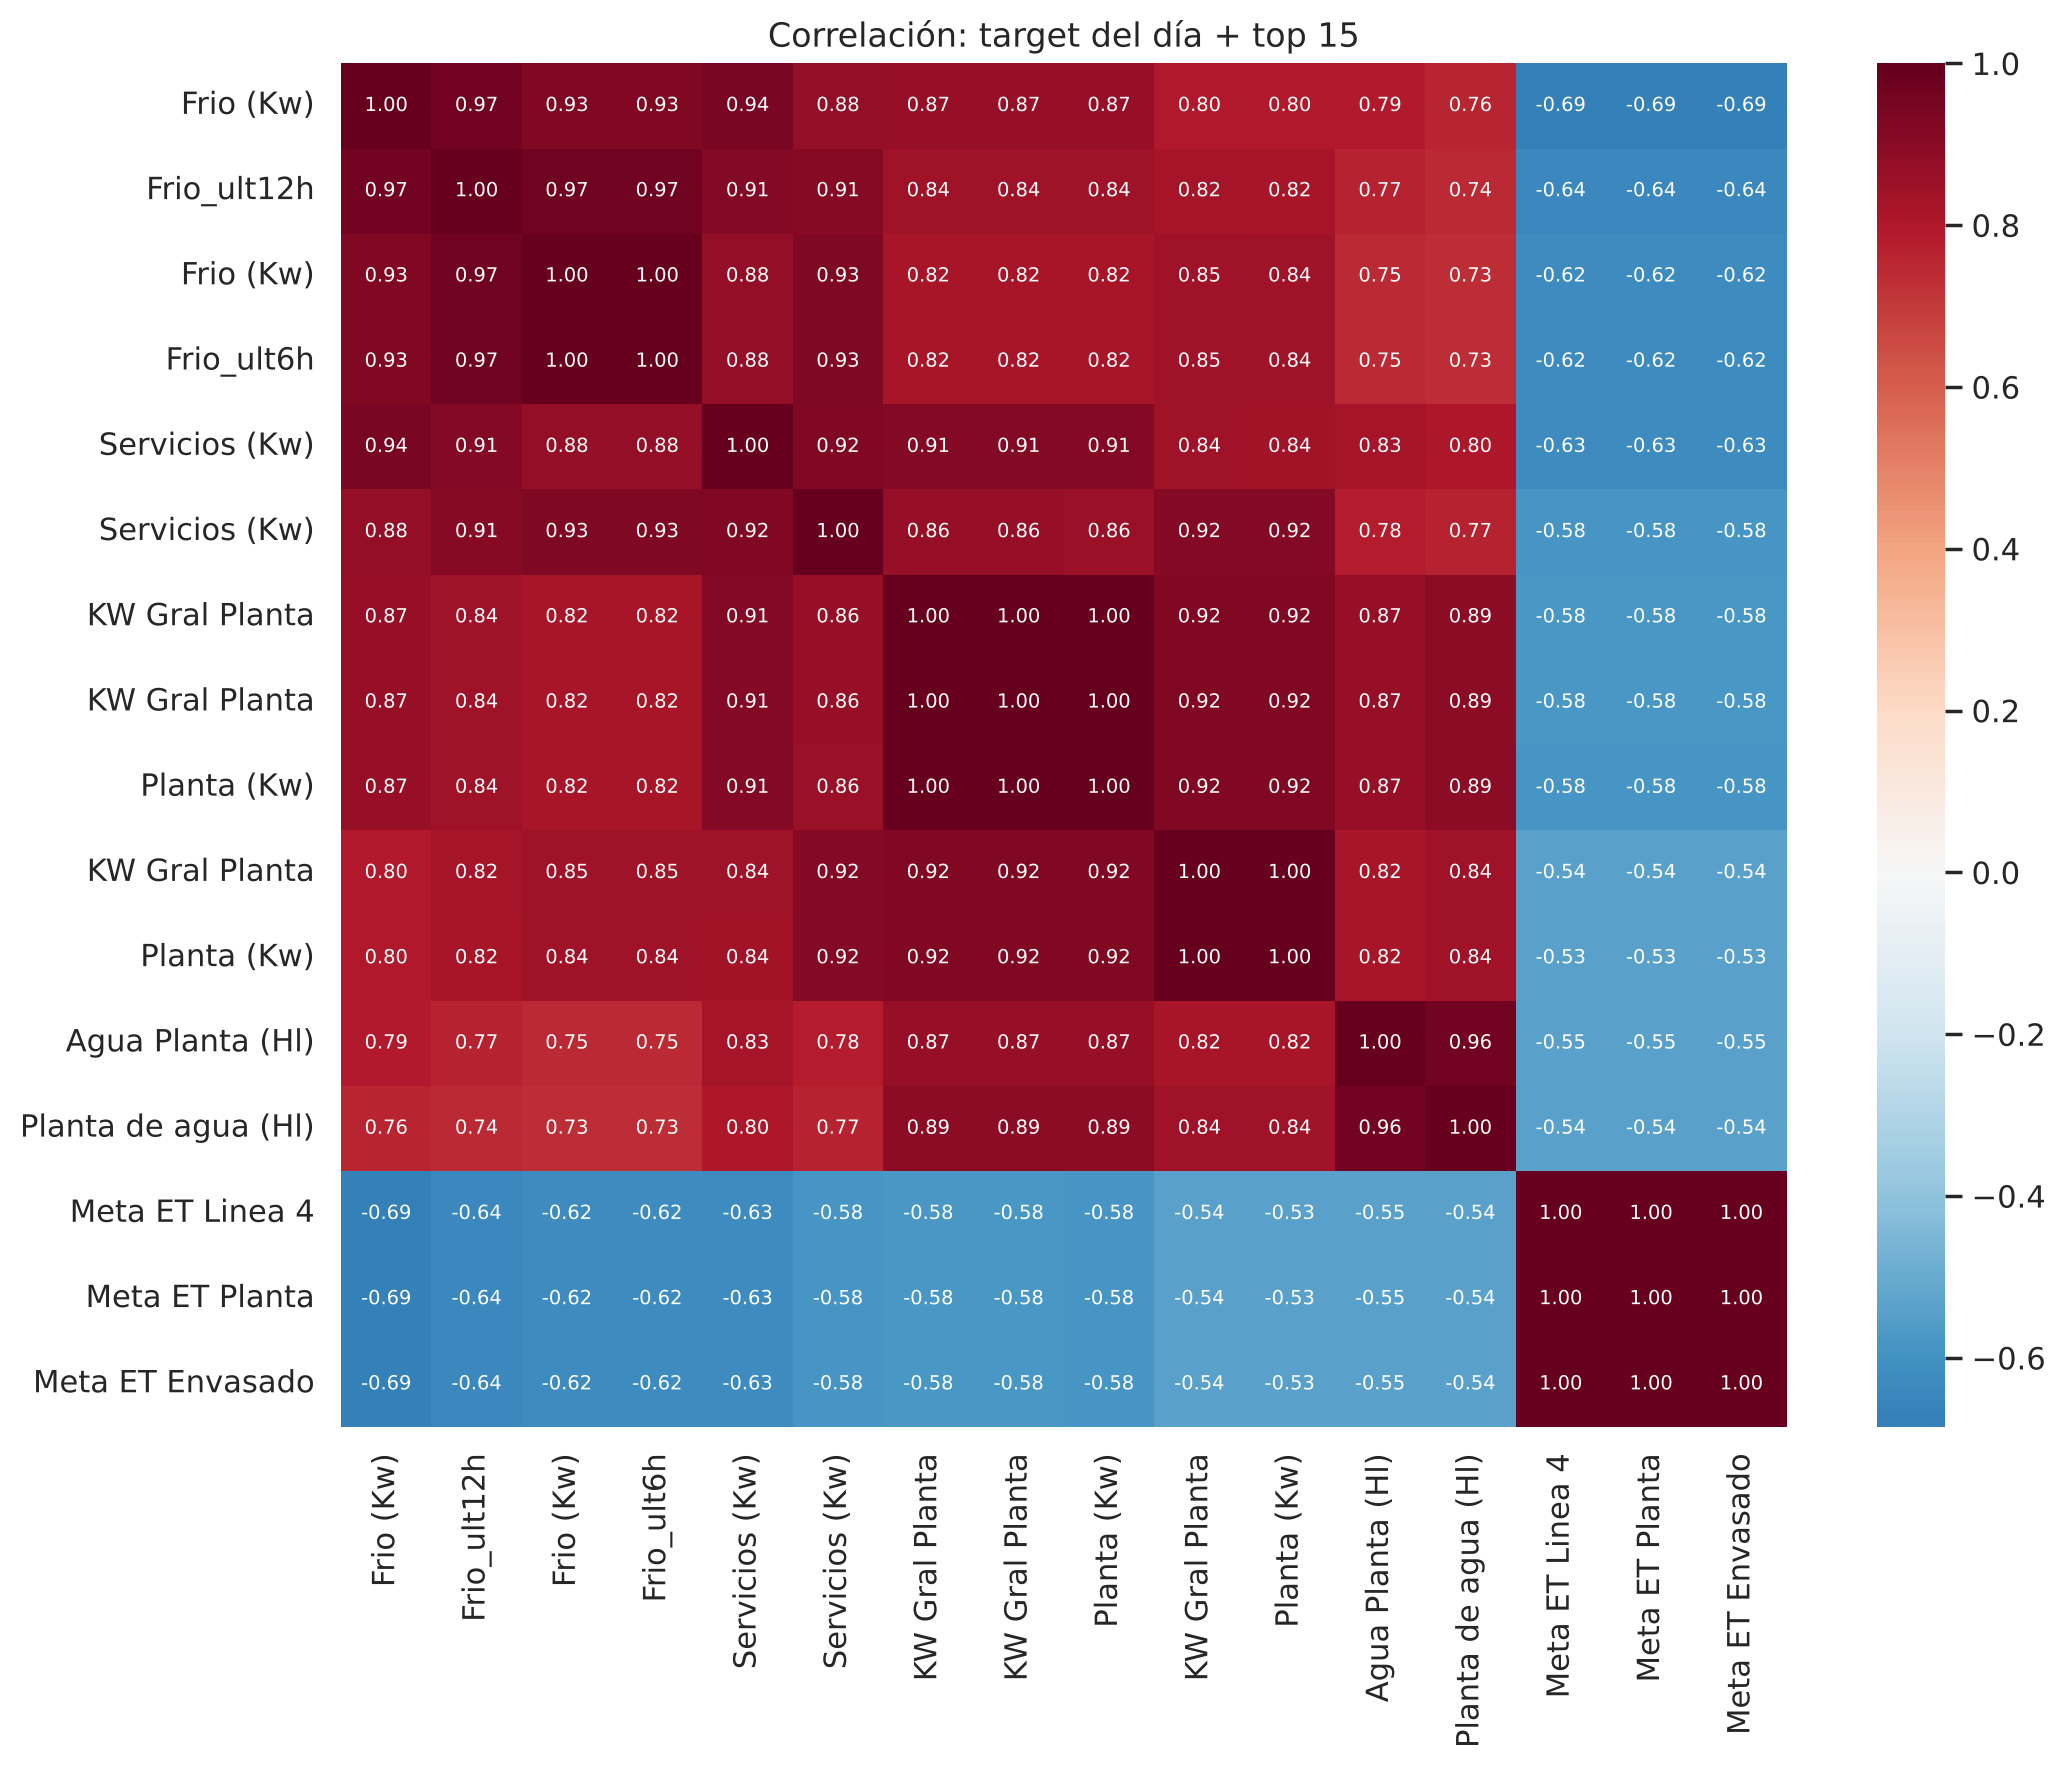

In [18]:
m = valid[[T, *top15]].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(m, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            xticklabels=[c.split("__")[1][:22] for c in m.columns], yticklabels=[c.split("__")[1][:22] for c in m.index])
plt.title("Correlación: target del día + top 15"); plt.tight_layout(); plt.savefig(FIG / "heatmap_top15.png", dpi=120); plt.show()

### Variables casi idénticas al objetivo (compresores Mycom)

In [19]:
myc = [c for c in valid.columns if "Mycom" in c]
suma = valid[myc].sum(axis=1, min_count=len(myc))
print(f"corr(suma Mycom 1-7, Frio mismo día) = {suma.corr(valid[T]):.4f}  | por año:",
      pd.DataFrame({"s": suma, "f": valid[T]}).groupby(valid.index.year).apply(lambda d: round(d.s.corr(d.f), 3)).to_dict())
print(f"corr(suma Mycom 1-7, Frio día siguiente) = {suma.corr(y_next.reindex(valid.index)):.4f}")
print(f"corr(Frio hoy, Frio día siguiente)        = {valid[T].corr(y_next.reindex(valid.index)):.4f}")

corr(suma Mycom 1-7, Frio mismo día) = 0.9762  | por año: {2020: 0.993, 2021: 0.962, 2022: 0.982, 2023: 0.986}
corr(suma Mycom 1-7, Frio día siguiente) = 0.8306
corr(Frio hoy, Frio día siguiente)        = 0.8537


La suma de los 7 compresores correlaciona 0,98-0,99 con `Frio` del mismo día en 2020, 2022 y 2023 (0,96 en 2021; 0,976 en el conjunto): es el mismo sistema físico medido desde
*Totalizadores Energia*. Usar su valor **de hoy** sería legítimo, pero no aporta nada que `Frio` de hoy no tenga
(predice el día siguiente igual o peor) y obliga a exigir 7 columnas más en el archivo de test. **No entra.**

### Multicolinealidad entre predictores candidatos

In [20]:
cand_raw = [c for c in top15 if not c.startswith("KPI__Meta")]
Xv = valid[cand_raw].dropna()
Xv = (Xv - Xv.mean()) / Xv.std()
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=cand_raw).sort_values(ascending=False)
vif.round(1).to_frame("VIF")

,VIF
EE__Frio (Kw)__ult6h,1.000800e+15
EE__Frio_ult6h,1.000800e+15
TEN__KW Gral Planta,1.000800e+15
EE__KW Gral Planta,1.000800e+15
EE__KW Gral Planta__ult6h,3.540900e+03
EE__Planta (Kw)__ult6h,3.379500e+03
EE__Planta (Kw),2.457000e+03
EE__Servicios (Kw)__ult6h,3.500000e+01
EE__Frio_ult12h,2.970000e+01
EE__Servicios (Kw),2.710000e+01


VIF muy altos: varias variables miden lo mismo (p. ej. `Aire Producido` y `Totalizador Sistema Kaeser`; los transformadores
contienen a las áreas). Por eso en la Fase 2 se usa una selección que penaliza redundancia (LASSO, RFE) y modelos
regularizados (Ridge/Lasso).

## 1.4 Visualizaciones requeridas

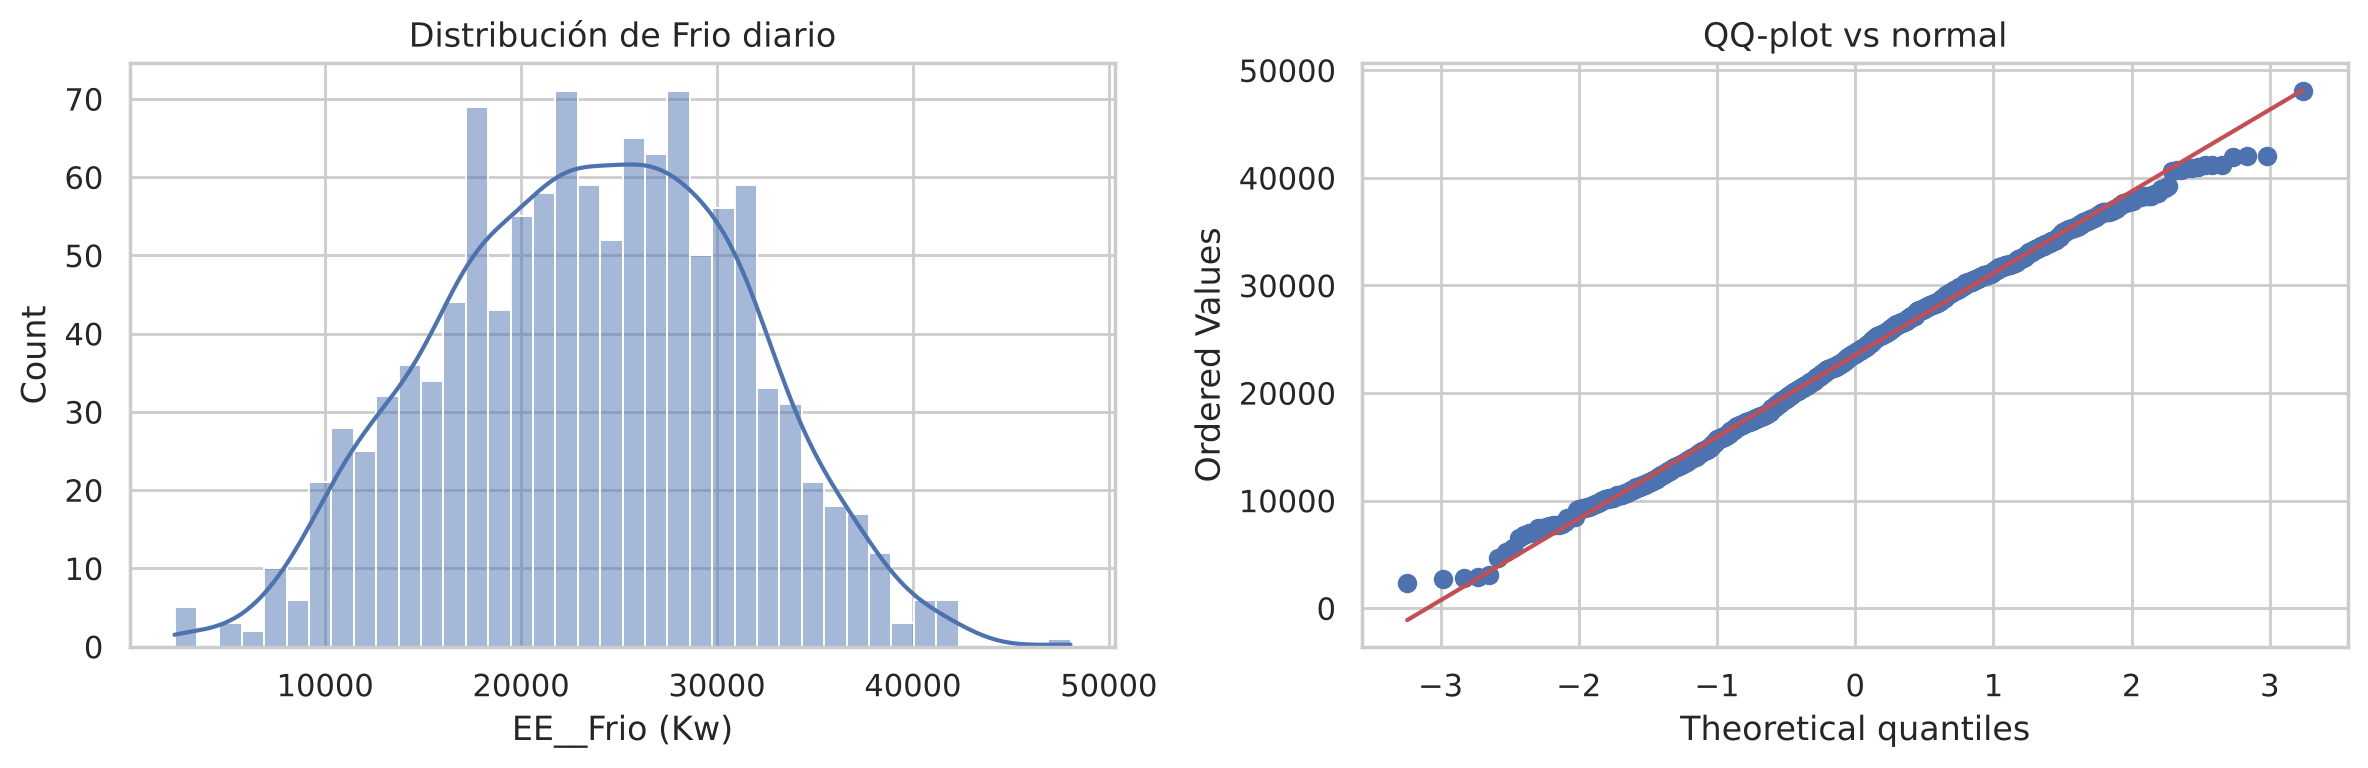

asimetría=-0.07  curtosis=-0.44  Shapiro p=4.67e-02


In [21]:
x = s.dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x, bins=40, kde=True, ax=ax[0]); ax[0].set_title("Distribución de Frio diario")
stats.probplot(x, dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot vs normal")
plt.tight_layout(); plt.savefig(FIG / "distribucion_target.png", dpi=120); plt.show()
print(f"asimetría={stats.skew(x):.2f}  curtosis={stats.kurtosis(x):.2f}  Shapiro p={stats.shapiro(x.sample(500, random_state=SEMILLA)).pvalue:.2e}")

La distribución es simétrica (asimetría ≈ 0) y más aplanada que una normal (curtosis < 0): es la mezcla de un régimen de invierno y otro de verano.
Después de la limpieza no quedan colas pesadas, así que no hace falta transformar el target (por ejemplo con log).

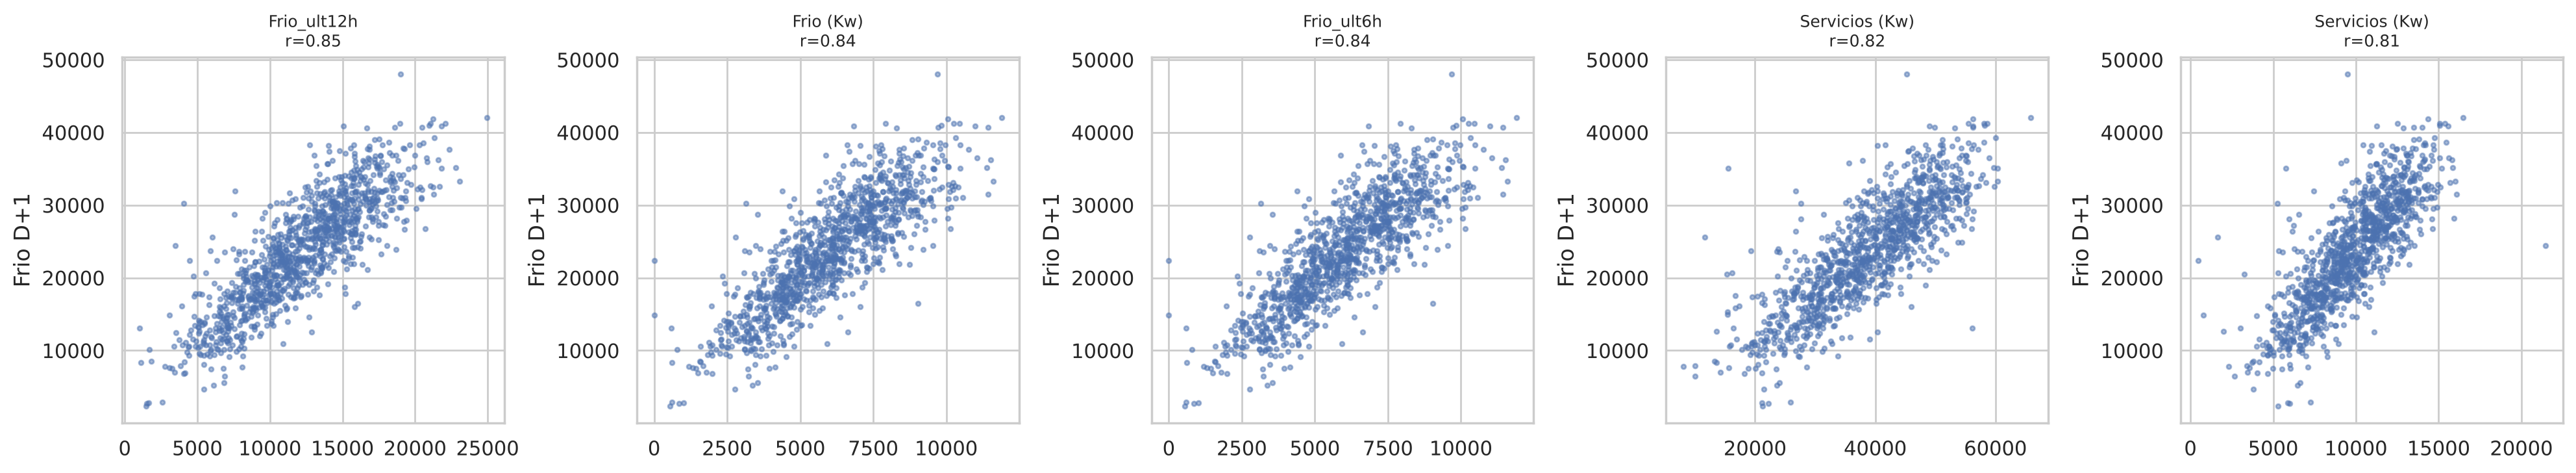

In [22]:
top5 = [c for c in top15 if not c.startswith("KPI__Meta")][:5]
fig, axs = plt.subplots(1, 5, figsize=(20, 3.8))
for a, c in zip(axs, top5):
    a.scatter(valid[c], y_next.reindex(valid.index), s=6, alpha=.5)
    a.set_title(f"{c.split('__')[1][:25]}\nr={corr.loc[c, 'dia_siguiente(y)']:.2f}", fontsize=9); a.set_ylabel("Frio D+1")
plt.tight_layout(); plt.savefig(FIG / "scatter_top5.png", dpi=120); plt.show()

### Consumo por área de la planta

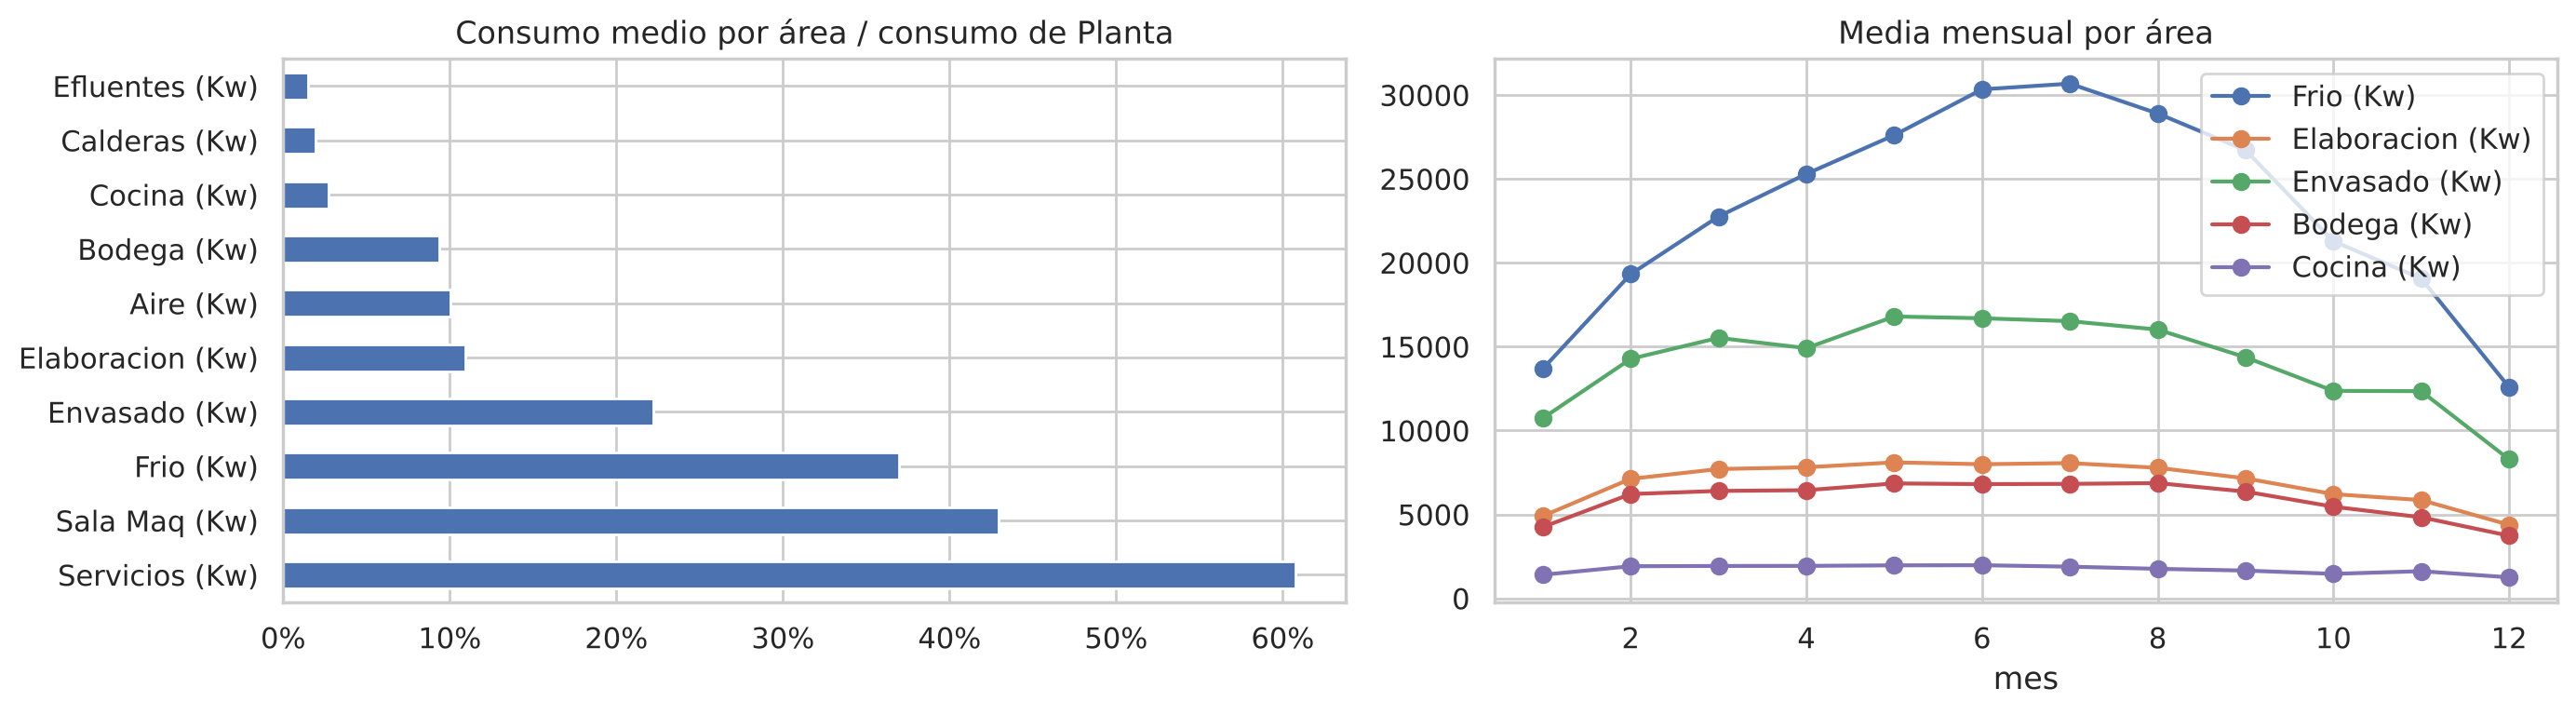

,corr con Frio (mismo día)
Servicios (Kw),0.94
Elaboracion (Kw),0.73
Bodega (Kw),0.62
Aire (Kw),0.61
Envasado (Kw),0.55
Cocina (Kw),0.45
Sala Maq (Kw),0.42
Efluentes (Kw),0.02
Calderas (Kw),-0.03


In [23]:
areas = ["Frio (Kw)", "Elaboracion (Kw)", "Envasado (Kw)", "Servicios (Kw)", "Sala Maq (Kw)", "Aire (Kw)", "Calderas (Kw)", "Efluentes (Kw)", "Bodega (Kw)", "Cocina (Kw)"]
A = valid[[f"EE__{a}" for a in areas]]; A.columns = areas
share = (A.mean() / valid["EE__Planta (Kw)"].mean()).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
share.plot.barh(ax=ax[0], title="Consumo medio por área / consumo de Planta"); ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
A[["Frio (Kw)", "Elaboracion (Kw)", "Envasado (Kw)", "Bodega (Kw)", "Cocina (Kw)"]].groupby(A.index.month).mean().plot(ax=ax[1], marker="o", title="Media mensual por área")
ax[1].set_xlabel("mes")
plt.tight_layout(); plt.savefig(FIG / "consumo_por_area.png", dpi=120); plt.show()
A.corr()["Frio (Kw)"].drop("Frio (Kw)").sort_values(ascending=False).round(2).to_frame("corr con Frio (mismo día)")

Frío es la mayor carga individual de la planta y la única con una estacionalidad tan fuerte. Las áreas son *partes anidadas*:
`Servicios` contiene al frío (por eso correlaciona 0,94 con él), `Elaboración` y `Bodega` (fermentación y maduración) lo acompañan,
mientras que `Envasado` y `Calderas` no se mueven con él.

## Conclusiones del EDA
1. **Datos:** 3 archivos solapados que, unificados, cubren 2020-07-01 → 2023-10-26 (calendario completo). La regla de
   desempate (día válido > extracción más reciente) solo decide en un puñado de fechas: el resto coincide exactamente.
2. **Registros problemáticos:** jornadas apiladas en fin de mes, días incompletos, días sin reinicio, totales del orden del millón
   y saltos espurios horarios. Se recupera todo lo que se puede recuperar con un método validado (Fase 2): saltos e imposibles
   se reconstruyen, el arrastre sin reinicio se descuenta y los días que terminan a las 23:00 se completan.
3. **Total diario = 23:59**, justificado por la documentación y porque el 23:00 pierde ~4 % del día.
4. **Estacionalidad anual dominante** (verano > 2x invierno) → `doy_cos` y medias móviles del propio Frio.
5. **Patrón semanal no confirmado** (0,5 % de la varianza, p ≈ 0,42) → se descartan `dia_semana` y `fin_de_semana`.
6. **Variables redundantes con el objetivo:** suma de compresores Mycom (r > 0,98) → fuera; metas de KPI (correlación
   espuria por estacionalidad) → fuera; constantes/vacías → fuera.
7. **Candidatas para la Fase 2:** historia de Frio (nivel, lags, medias, ritmo de fin de día), áreas del tablero EE
   (todas las columnas de *Consolidado EE*, con su total, su consumo de las últimas 6 horas y su media de 7 días), condensadores, producción (mosto, bodega, filtrada,
   envasada), agua y aire, más ratios, eficiencia contra meta e interacciones con la estación.